# Predicting Household Food Insecurity in Sri Lanka Using Ensemble Machine Learning

**Research analysis notebook — seven classification models**

This notebook documents the existing project pipeline and **loads previously generated outputs without retraining or overwriting saved models**. It is intended to accompany `data_preprocessing.py`, `train_models.py`, `model_evaluation.py`, and the Streamlit dashboard (`app.py`).

**Research task:** Binary classification of household food insecurity, with `food_insecure = 1` indicating food insecurity and `0` indicating food security. The RF + ANN model is a **classification hybrid**, consistent with this target.

## 1. Environment and project paths

Run this notebook from the project root in VS Code, using the project's `.venv` kernel. Required files are in `results/`. Run `data_preprocessing.py` and the verified training workflow separately only if these results do not already exist.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "results").exists() and (PROJECT_DIR.parent / "results").exists():
    PROJECT_DIR = PROJECT_DIR.parent
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"
print("Project:", PROJECT_DIR)
print("Results directory exists:", RESULTS_DIR.exists())
print("Models directory exists:", MODELS_DIR.exists())

Project: /Users/nithakshidishara/SriLanka_Household_Food_Insecurity_EnsembleML
Results directory exists: True
Models directory exists: True


## 2. Research dataset and target definition

The research uses household survey modules, merged using the household identifier (`hhcode`) in `data_preprocessing.py`. The binary outcome is derived from six food-security survey responses (`l1_01` to `l1_06`): a household is labeled **1** when at least one answer is `1` (yes), and **0** when all six answers are `2` (no). Records that do not satisfy either rule are excluded. The target-generation script should be consulted for the exact implementation.

The cleaned modeling dataset excludes the identifier and target-source questions to reduce direct target leakage. Remaining predictors should still be reviewed for indirect leakage, survey skip codes, and missing-data semantics.

In [2]:
data_file = RESULTS_DIR / "cleaned_household_data.csv"
if not data_file.exists():
    raise FileNotFoundError(f"Missing {data_file}. Run data_preprocessing.py in the project first.")
df = pd.read_csv(data_file, low_memory=False)
assert "food_insecure" in df.columns, "Expected binary target 'food_insecure'"
print(f"Households: {len(df):,} | Columns: {df.shape[1]:,}")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}).head(20))

Households: 4,155 | Columns: 420


,hh_type,starttime,endtime,visit_date_r0,visit_date_r1,a_01_province,a_02_district,a_05,hhweight,ppweight,...,n2_02_6,n2_02_999,n2_02_998,n2_02_other,n2_03,n2_04,n2_05,n2_06,n2_07,food_insecure
0,3,"Feb 10, 2025 11:29:34 AM","Feb 13, 2025 1:47:22 AM",NaN,NaN,1,1.0,2,561.21030,2244.8413,...,0,0,0,NaN,0,NaN,0,NaN,0,0
1,3,"Feb 11, 2025 6:07:56 AM","Feb 11, 2025 5:27:14 PM",NaN,NaN,1,1.0,2,885.93280,885.9328,...,0,0,0,NaN,0,NaN,0,NaN,0,1
2,3,"Feb 7, 2025 7:14:32 AM","Feb 8, 2025 10:37:26 AM",NaN,NaN,1,1.0,2,1098.23200,1098.2320,...,0,0,0,NaN,0,NaN,0,NaN,1,0
3,2,"Feb 10, 2025 5:52:22 AM","Feb 12, 2025 11:59:28 AM","Feb 10, 2025","Feb 10, 2025",1,1.0,3,118.54024,592.7012,...,0,0,0,NaN,0,NaN,1,1.0,0,0
4,3,"Feb 7, 2025 8:19:24 AM","Feb 9, 2025 12:08:05 PM",NaN,NaN,1,1.0,2,885.93280,885.9328,...,0,0,0,NaN,0,NaN,0,NaN,0,0


,dtype,missing
hh_type,int64,0
starttime,str,0
endtime,str,0
visit_date_r0,str,1452
visit_date_r1,str,1452
a_01_province,int64,0
a_02_district,float64,0
a_05,int64,0
hhweight,float64,0
ppweight,float64,0


## 3. Exploratory data analysis (EDA)

,count,percent
food_insecure,,
0,1802,43.37
1,2353,56.63


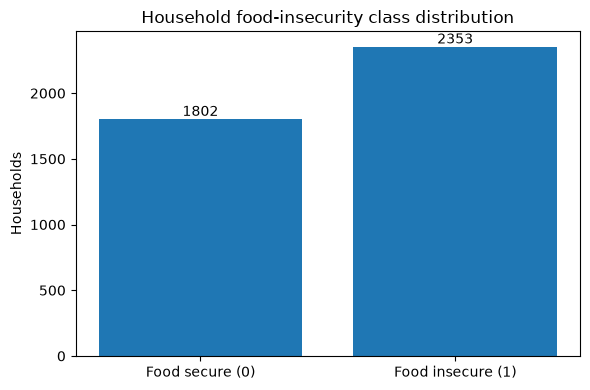

In [3]:
counts = df["food_insecure"].value_counts(dropna=False).sort_index()
display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Food secure (0)" if x == 0 else "Food insecure (1)" for x in counts.index], counts.values)
ax.set(title="Household food-insecurity class distribution", ylabel="Households")
for i, value in enumerate(counts.values):
    ax.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout(); plt.show()

Predictor count: 419
Numerical predictors: 375
Other predictors: 44


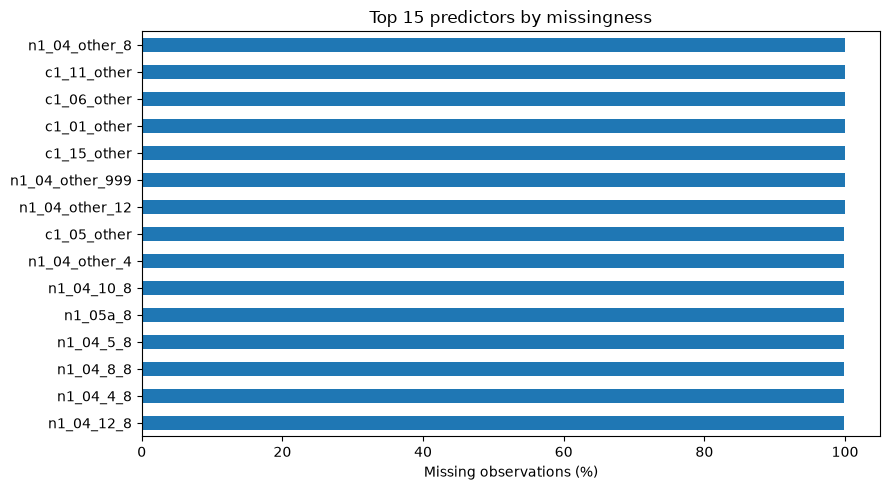

In [4]:
feature_df = df.drop(columns=["food_insecure"])
print("Predictor count:", feature_df.shape[1])
print("Numerical predictors:", len(feature_df.select_dtypes(include=[np.number, "bool"]).columns))
print("Other predictors:", len(feature_df.select_dtypes(exclude=[np.number, "bool"]).columns))
missing = feature_df.isna().mean().sort_values(ascending=False).head(15) * 100
fig, ax = plt.subplots(figsize=(9, 5))
missing.sort_values().plot.barh(ax=ax)
ax.set(xlabel="Missing observations (%)", title="Top 15 predictors by missingness")
plt.tight_layout(); plt.show()

## 4. Training and model methodology

The project's `train_models.py` is the source of truth for training. It performs an **80/20 stratified train/test split (`random_state=42`)**, fits preprocessing within model pipelines, and evaluates seven classifiers on the held-out test set. Numerical missing values are imputed with zero; categorical inputs are converted to strings, missing categories are labeled `__MISSING__`, and unknown categories are encoded as `-1`. These preprocessing assumptions require domain review.

| Model | Role / approach |
|---|---|
| Decision Tree | Baseline classifier |
| Bagging | Bootstrap aggregation of decision trees |
| Random Forest | Randomized tree ensemble |
| AdaBoost | Sequential boosting |
| XGBoost | Gradient-boosted trees |
| Stacking | Random Forest + XGBoost, logistic-regression meta-learner |
| RF + ANN Hybrid | Random Forest + multilayer perceptron, logistic-regression meta-learner |

**Hybrid detail:** The ANN branch uses `StandardScaler` after encoding, with hidden layers `(64, 32)`; both branches supply class probabilities to the logistic-regression meta-learner (`cv=3`). This is a hybrid **classifier**, not a regression model.

**Reproducibility:** This notebook intentionally does not call `train_models.py`, since doing so would overwrite existing `.pkl` models and evaluation CSVs. The saved outputs below represent the last completed training run, which may not have used identical hyperparameters to the current combined script.

In [5]:
expected = {
    "Decision Tree": "decision_tree", "Bagging": "bagging",
    "Random Forest": "random_forest", "AdaBoost": "adaboost",
    "XGBoost": "xgboost", "Stacking": "stacking",
    "RF + ANN Hybrid": "rf_ann_hybrid",
}
model_inventory = pd.DataFrame([
    {"Model": name, "Saved model exists": (MODELS_DIR / f"{key}.pkl").exists()}
    for name, key in expected.items()
])
display(model_inventory)

,Model,Saved model exists
0,Decision Tree,True
1,Bagging,True
2,Random Forest,True
3,AdaBoost,True
4,XGBoost,True
5,Stacking,True
6,RF + ANN Hybrid,True


## 5. Model evaluation — held-out test results

In [6]:
comparison_file = RESULTS_DIR / "model_comparison.csv"
if not comparison_file.exists():
    raise FileNotFoundError(f"Missing {comparison_file}")
comparison = pd.read_csv(comparison_file)
required_metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
assert set(["Model"] + required_metrics).issubset(comparison.columns), "Unexpected model comparison columns"
display(comparison.sort_values("F1 Score", ascending=False).reset_index(drop=True).round(4))
print("Models in saved comparison:", len(comparison))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Bagging,0.6907,0.6877,0.8323,0.7531,0.7267
1,XGBoost,0.6895,0.6926,0.8132,0.7480,0.7285
2,RF + ANN Hybrid,0.6835,0.6857,0.8153,0.7449,0.7270
3,Random Forest,0.6823,0.6957,0.7813,0.7360,0.7242
4,AdaBoost,0.6643,0.6727,0.7941,0.7283,0.7151
5,Stacking,0.6691,0.6822,0.7792,0.7275,0.7298
6,Decision Tree,0.6318,0.6525,0.7495,0.6976,0.6435


Models in saved comparison: 7


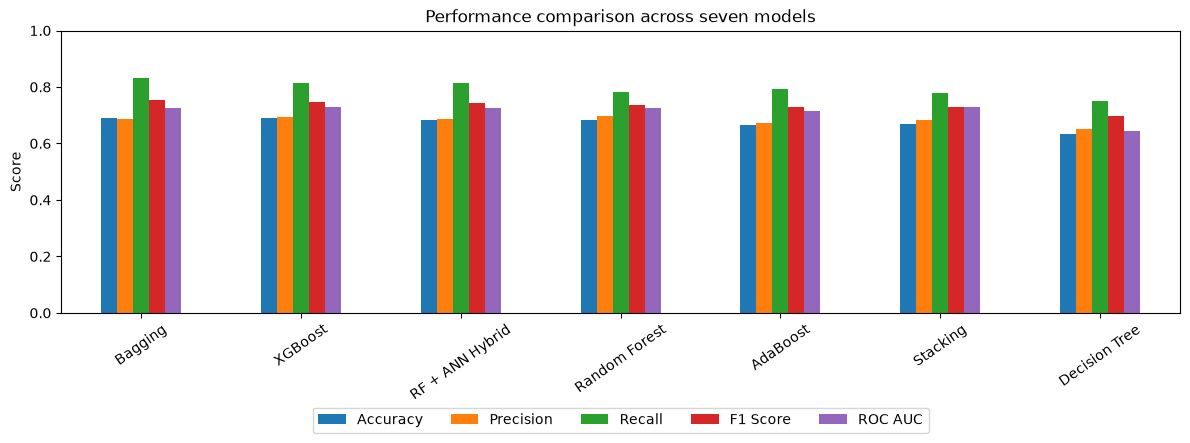

In [7]:
plot_df = comparison.set_index("Model")[required_metrics]
ax = plot_df.plot(kind="bar", figsize=(12, 5), ylim=(0, 1), rot=35)
ax.set(title="Performance comparison across seven models", ylabel="Score", xlabel="")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=5)
plt.tight_layout(); plt.show()

### Interpreting the metrics

- **Accuracy:** Fraction of all correct predictions.
- **Precision:** Fraction of predicted food-insecure households that are truly food-insecure.
- **Recall:** Fraction of food-insecure households successfully identified.
- **F1 score:** Harmonic mean of precision and recall.
- **ROC AUC:** Ranking/discrimination across decision thresholds.

In a food-insecurity screening context, **recall** can be important because missed food-insecure households are consequential. However, the cost of false positives and precision must also be considered. Avoid claiming that moderate scores imply deployment readiness.

In [8]:
for metric in required_metrics:
    best = comparison.loc[comparison[metric].idxmax()]
    print(f"Highest {metric}: {best['Model']} ({best[metric]:.4f})")

Highest Accuracy: Bagging (0.6907)
Highest Precision: Random Forest (0.6957)
Highest Recall: Bagging (0.8323)
Highest F1 Score: Bagging (0.7531)
Highest ROC AUC: Stacking (0.7298)


## 6. Confusion matrices and ROC curves from saved test predictions

Held-out prediction rows: 831
Available prediction columns: ['actual', 'decision_tree_pred', 'decision_tree_prob', 'bagging_pred', 'bagging_prob', 'random_forest_pred', 'random_forest_prob', 'adaboost_pred', 'adaboost_prob', 'xgboost_pred', 'xgboost_prob', 'stacking_pred', 'stacking_prob', 'rf_ann_hybrid_pred', 'rf_ann_hybrid_prob']


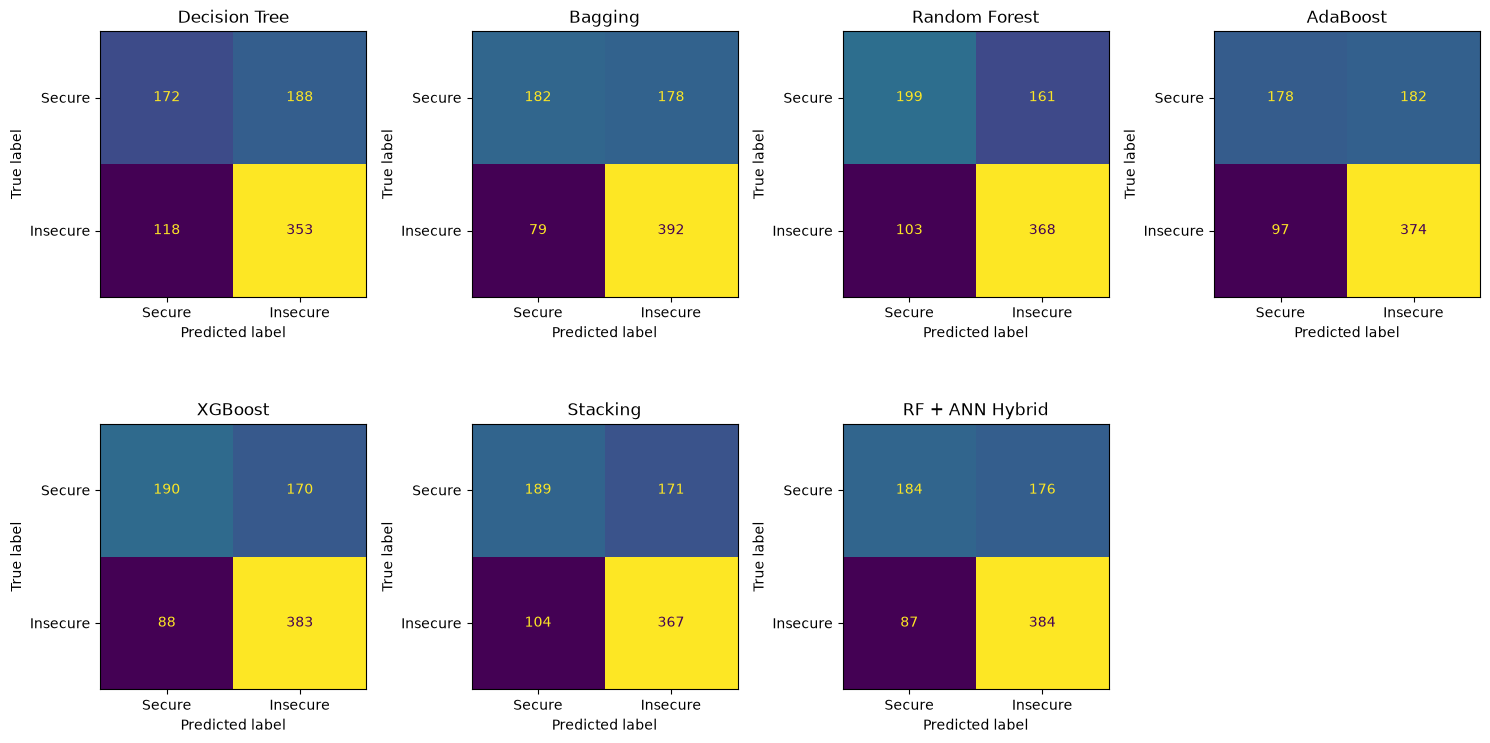

In [9]:
pred_file = RESULTS_DIR / "test_predictions.csv"
if not pred_file.exists():
    raise FileNotFoundError(f"Missing {pred_file}")
pred = pd.read_csv(pred_file)
assert "actual" in pred.columns, "Missing 'actual' column"
print("Held-out prediction rows:", len(pred))
print("Available prediction columns:", list(pred.columns))
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (name, key) in zip(axes.flat, expected.items()):
    col = f"{key}_pred"
    if col in pred.columns:
        cm = confusion_matrix(pred["actual"], pred[col], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Secure", "Insecure"]).plot(ax=ax, colorbar=False, values_format="d")
        ax.set_title(name)
    else:
        ax.text(0.5, 0.5, f"Missing {col}", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off")
for ax in list(axes.flat)[len(expected):]: ax.axis("off")
plt.tight_layout(); plt.show()

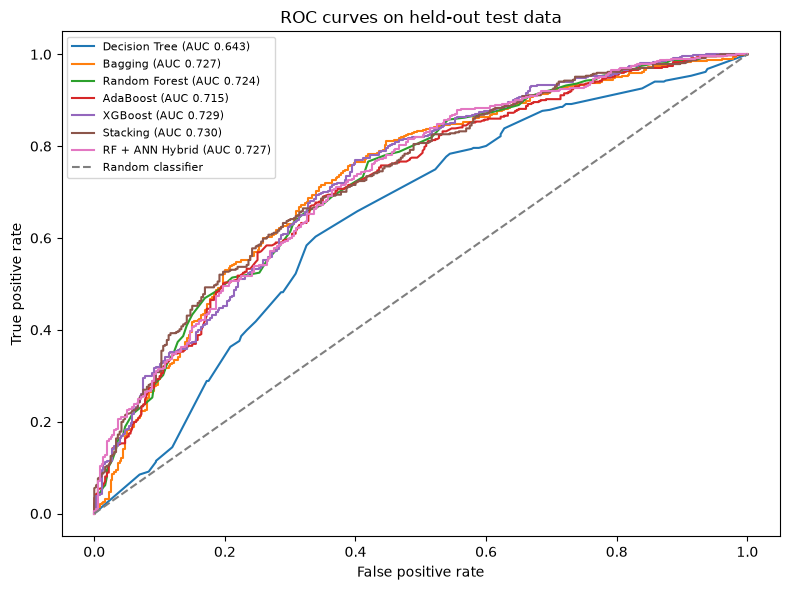

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
plotted = 0
for name, key in expected.items():
    col = f"{key}_prob"
    if col not in pred.columns:
        print("ROC skipped; missing:", col)
        continue
    fpr, tpr, _ = roc_curve(pred["actual"], pred[col])
    ax.plot(fpr, tpr, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
    plotted += 1
ax.plot([0, 1], [0, 1], "--", label="Random classifier")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves on held-out test data")
if plotted: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Feature importance (where available)

Feature-importance files: ['decision_tree_feature_importance.csv', 'random_forest_feature_importance.csv', 'xgboost_feature_importance.csv']

 decision_tree_feature_importance.csv


,Feature,Importance
0,numeric__d_12,0.185913
1,numeric__d_03,0.083081
2,numeric__d_15c,0.050365
3,numeric__c1_20,0.034311
4,numeric__c1_03,0.029937
5,numeric__d_06,0.029465
6,numeric__d_21b,0.026245
7,numeric__d_17,0.025524
8,numeric__c1_21,0.020214
9,numeric__d_22,0.020197



 random_forest_feature_importance.csv


,Feature,Importance
0,numeric__c1_03,0.020608
1,numeric__d_15b,0.019850
2,numeric__d_03,0.019677
3,numeric__d_15c,0.019588
4,numeric__c1_18,0.018245
5,numeric__c1_20,0.018079
6,numeric__c1_21,0.017766
7,numeric__c1_02,0.017555
8,numeric__c1_22,0.017116
9,numeric__d_15a,0.016059



 xgboost_feature_importance.csv


,Feature,Importance
0,numeric__d_12,0.104413
1,numeric__d_15,0.027632
2,numeric__d_16,0.019686
3,numeric__d_06,0.017199
4,numeric__d_14,0.016317
5,numeric__d_03,0.015195
6,numeric__d_22,0.015153
7,numeric__d_09_5,0.014489
8,categorical__d_07_3,0.013036
9,numeric__c1_09,0.012474


random_forest_feature_importance.png


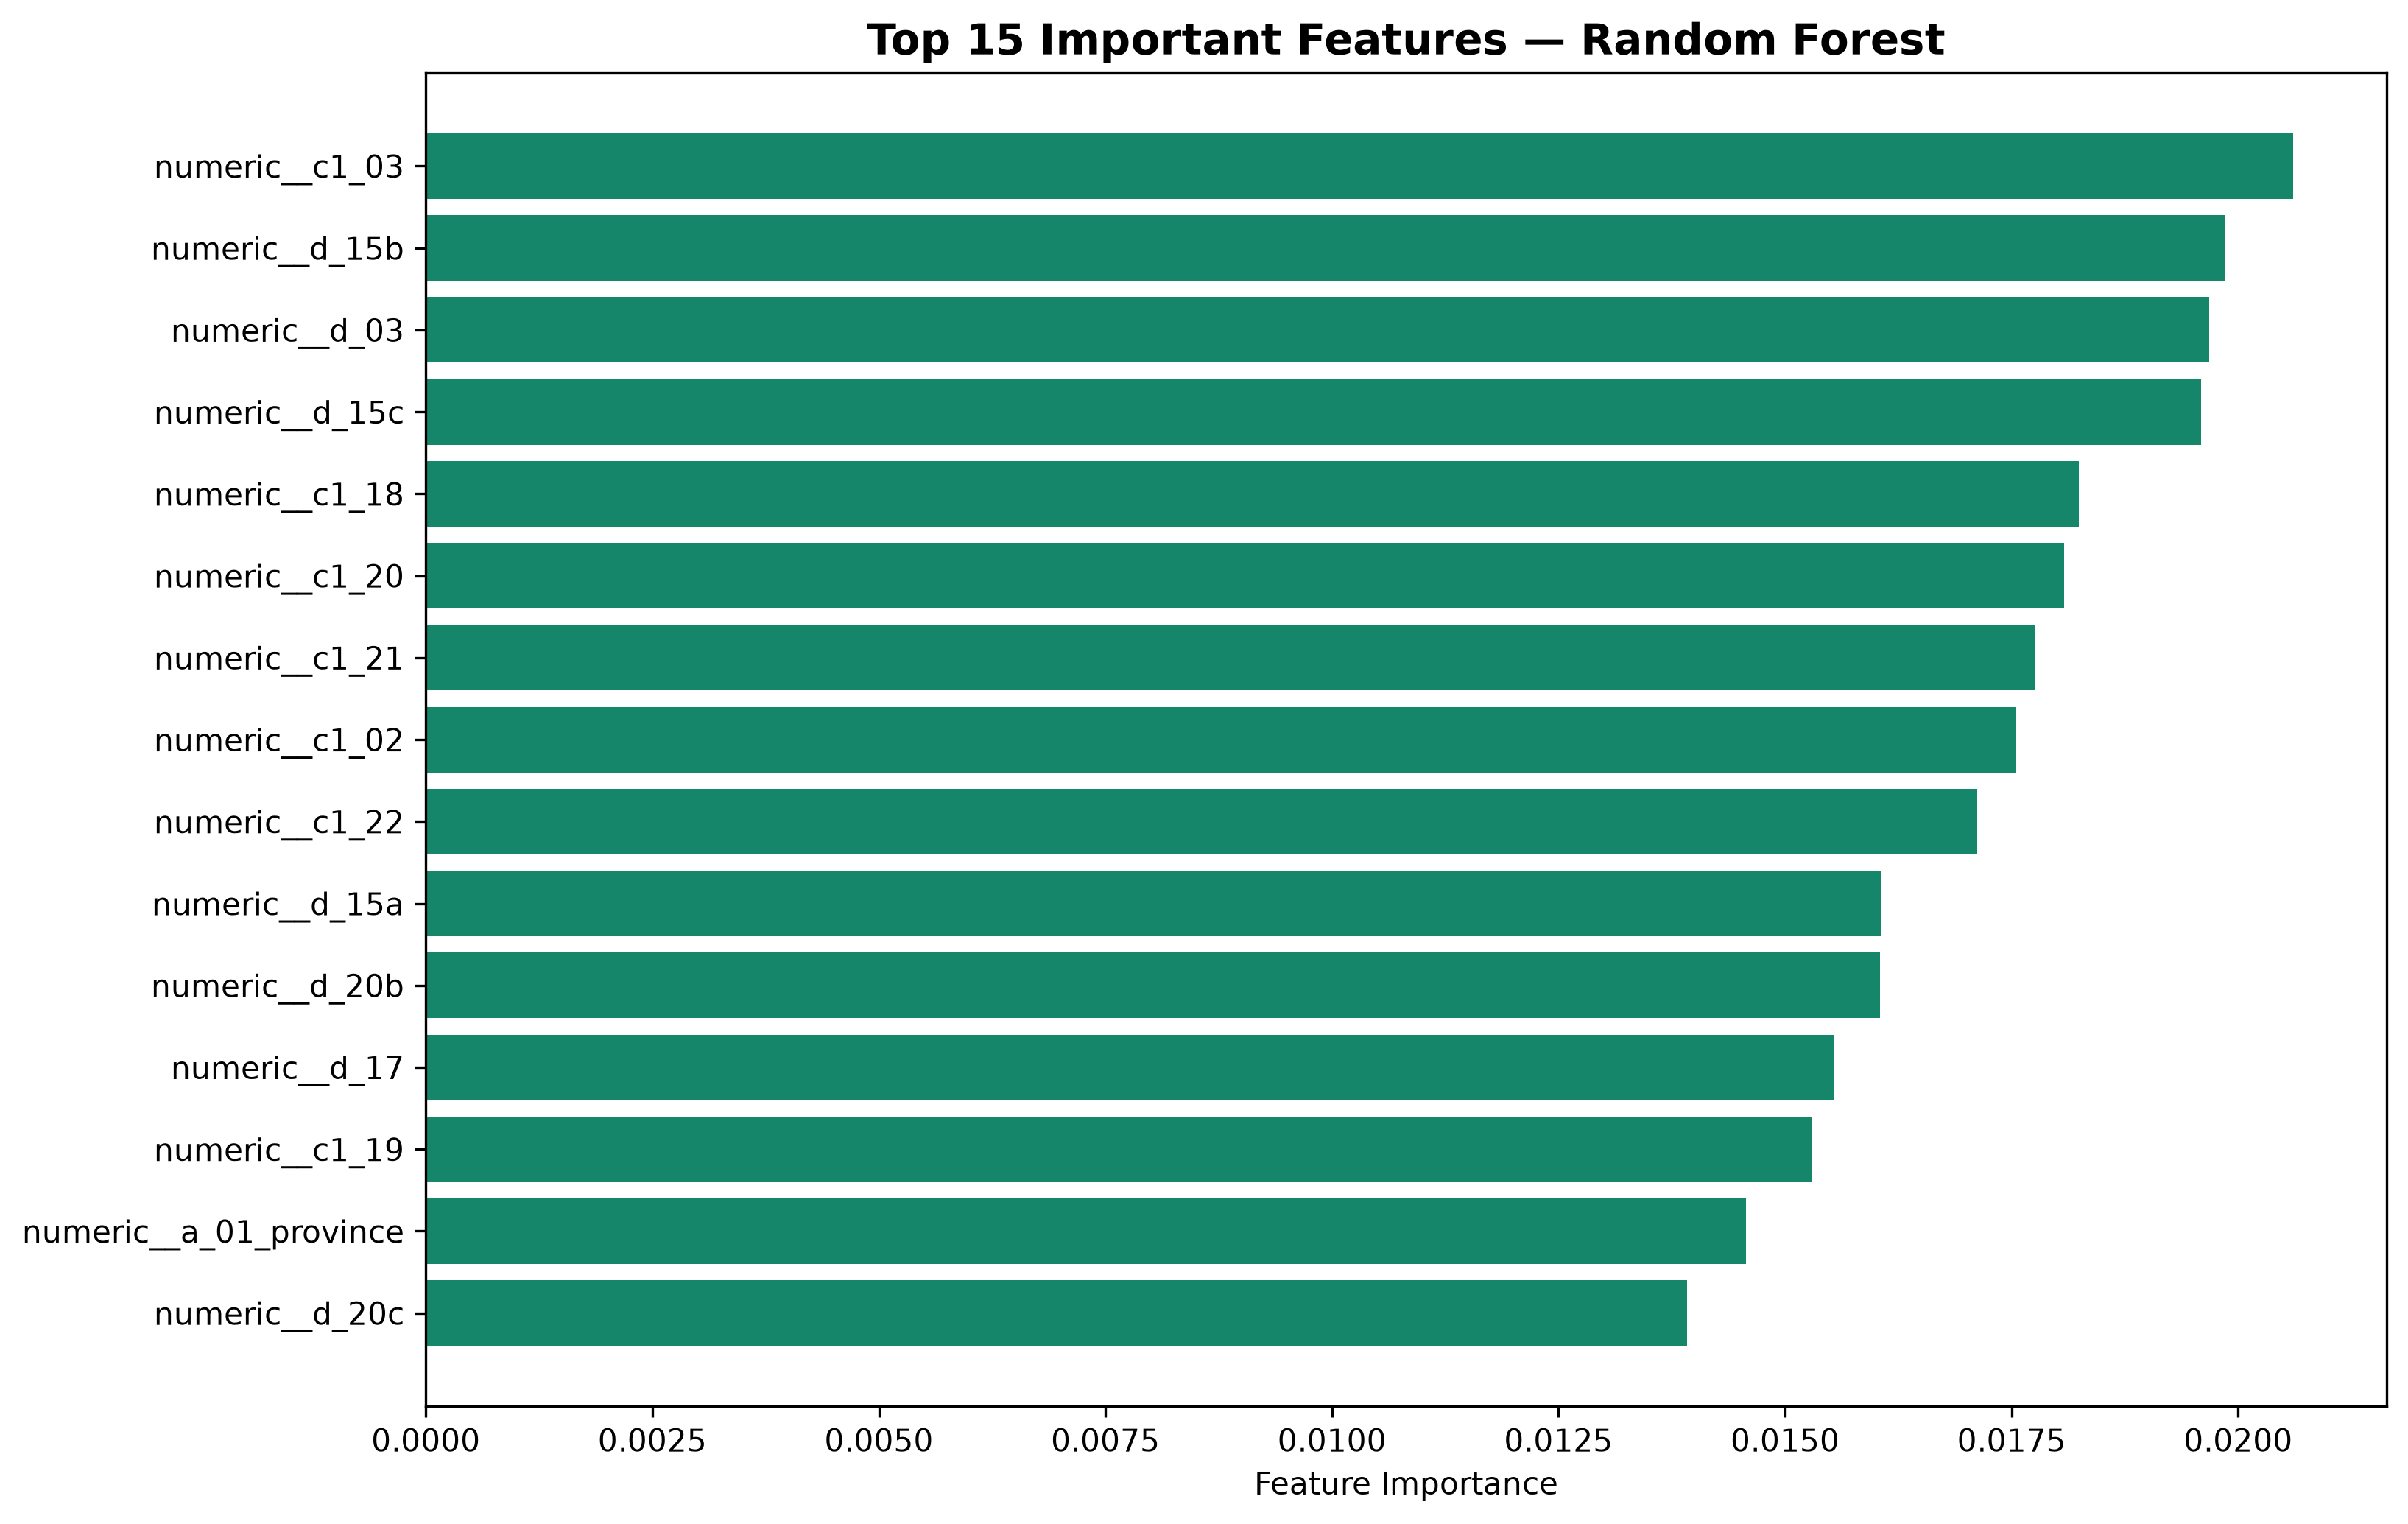

xgboost_feature_importance.png


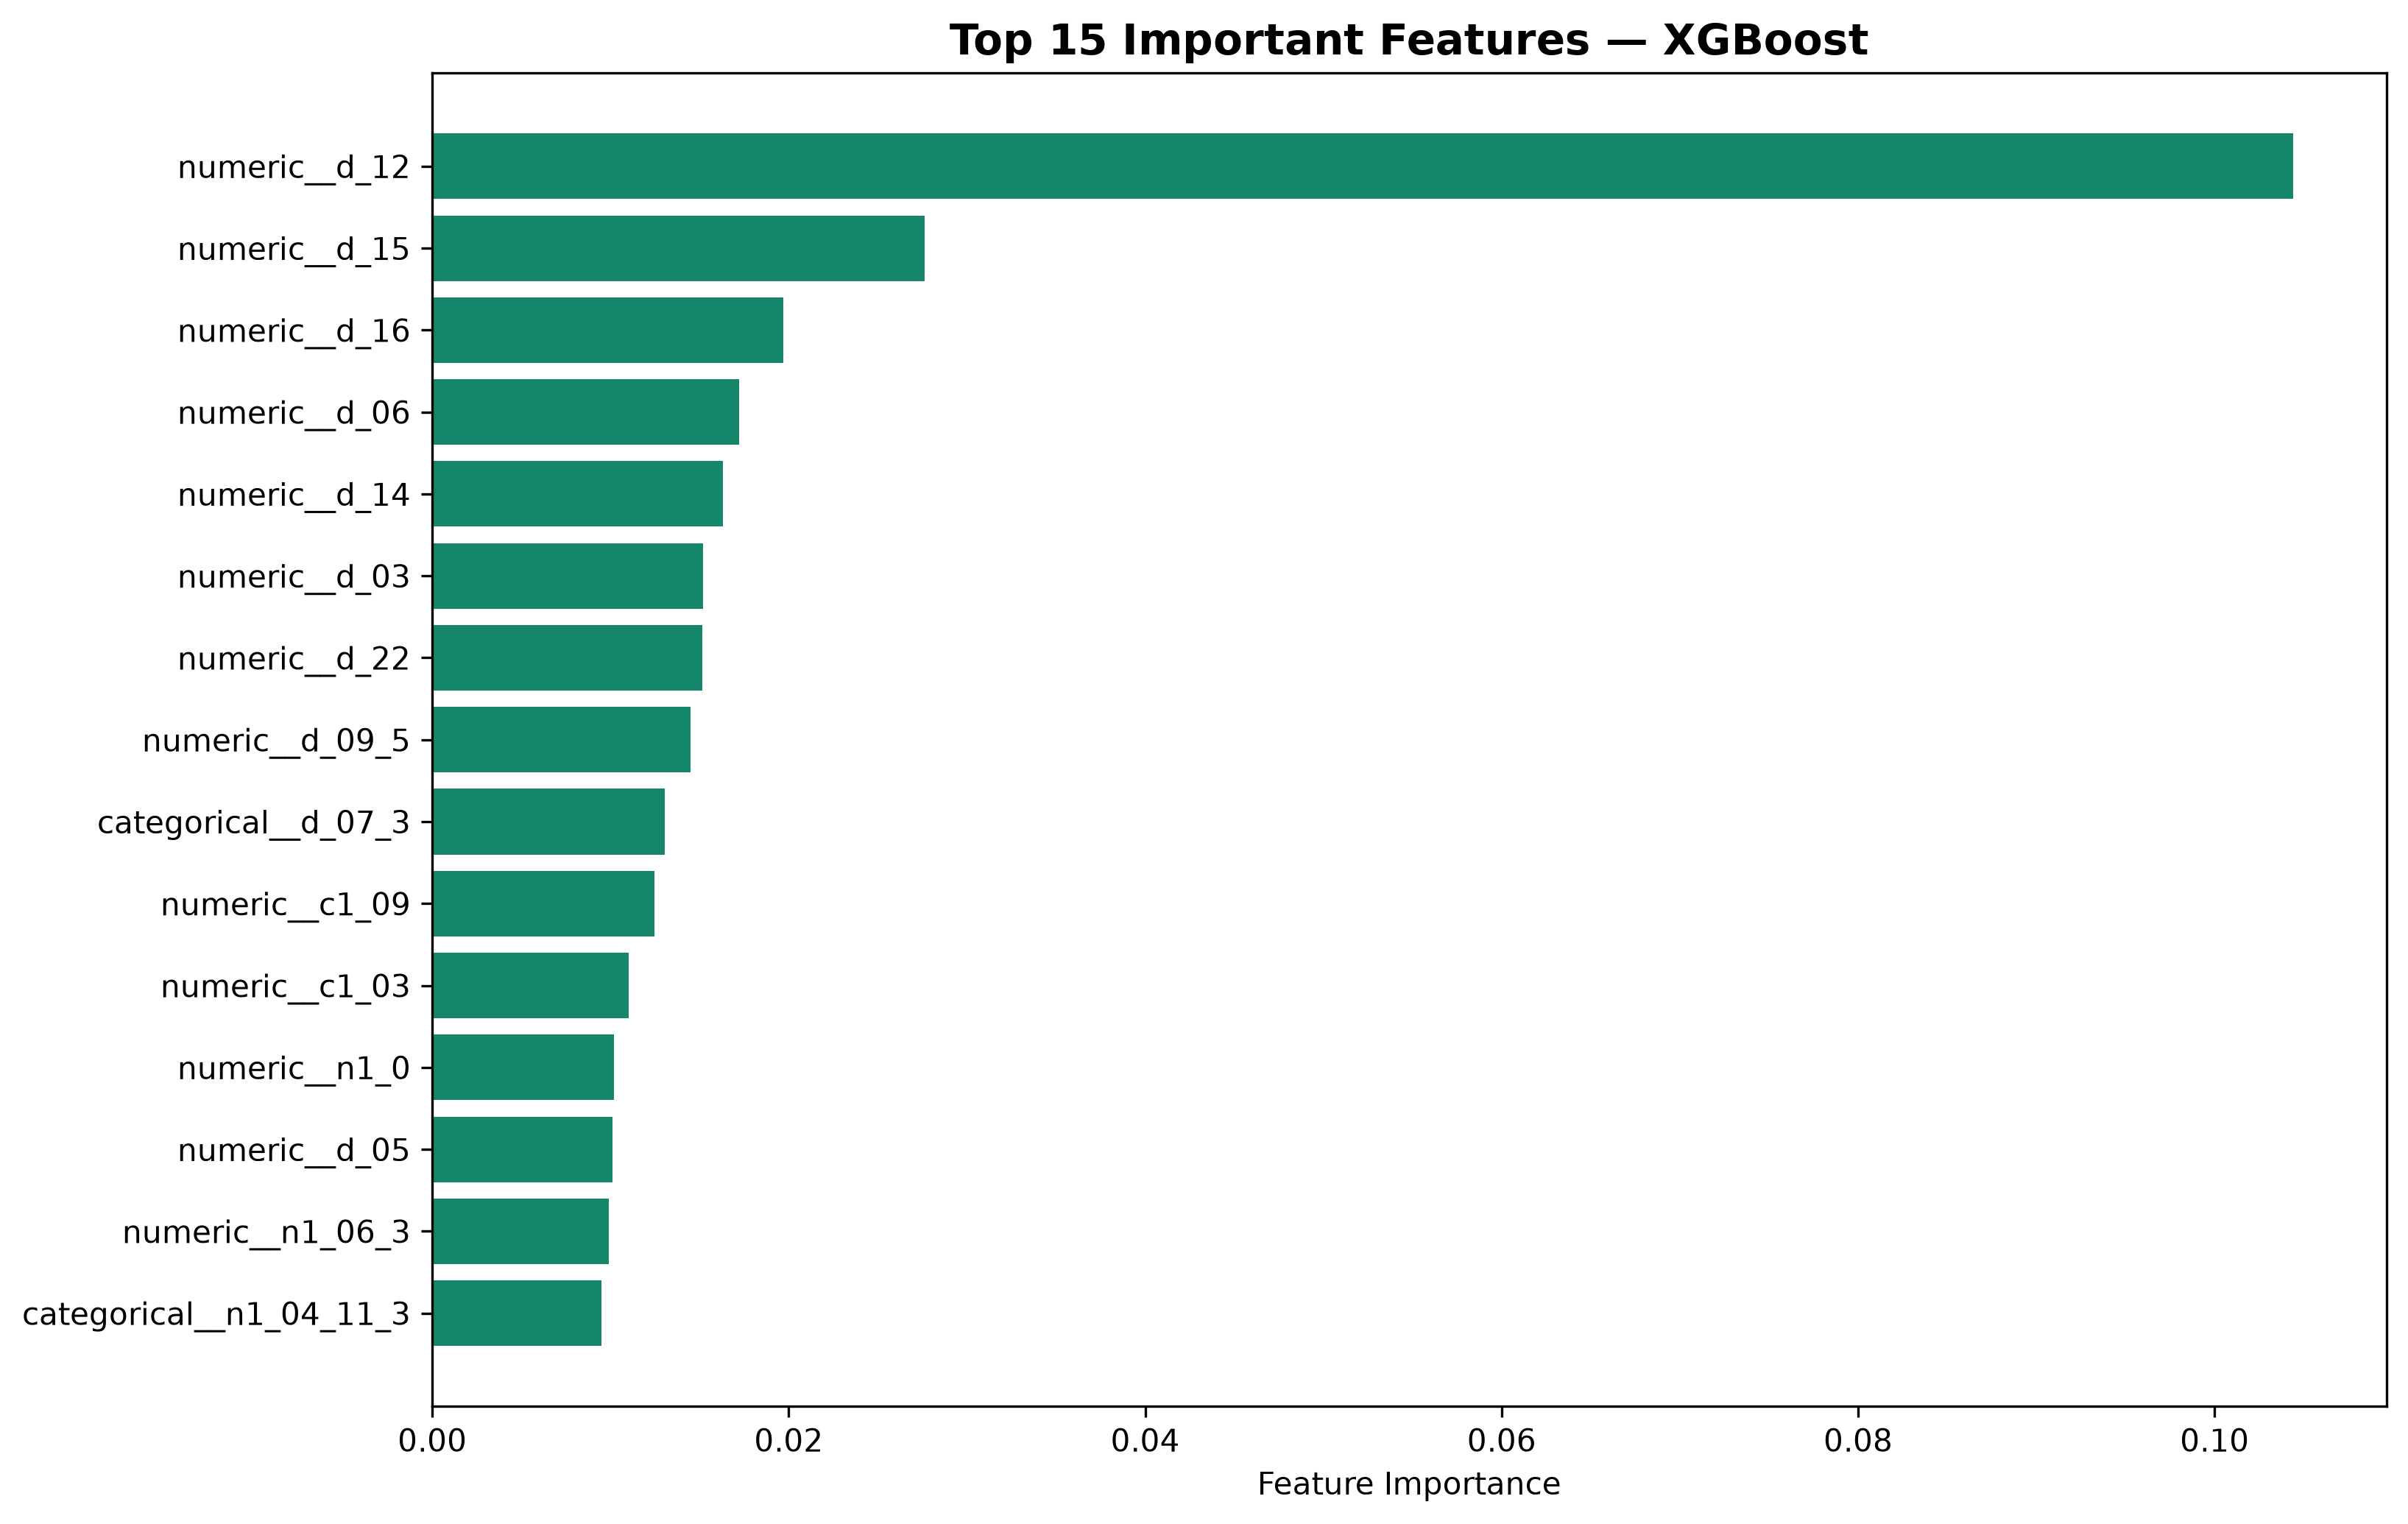

In [11]:
importance_files = sorted(RESULTS_DIR.glob("*_feature_importance.csv"))
print("Feature-importance files:", [p.name for p in importance_files])
for file in importance_files[:3]:
    print("\n", file.name)
    display(pd.read_csv(file).head(10))

for filename in ["random_forest_feature_importance.png", "xgboost_feature_importance.png"]:
    image_file = RESULTS_DIR / filename
    if image_file.exists():
        print(filename)
        display(Image(filename=str(image_file), width=800))

## 8. Results discussion and research limitations

Use the **computed table above** to identify the highest-scoring models. Different metrics may favor different models; do not select a single winner without specifying the selection criterion.

**Key limitations and checks:**

1. The target is constructed from six survey responses; it is not a validated continuous food-insecurity severity score.
2. The evaluation uses one stratified 80/20 split. Repeated or external validation would improve confidence.
3. Zero imputation, ordinal encoding, and survey-specific missing-value codes may influence predictions.
4. Model performance indicates predictive association, not causality.
5. Check household sampling, representativeness, fairness, and leakage before policy or operational use.
6. Confirm that saved results correspond to the exact code and hyperparameters reported in the final submission; the current combined training script may differ from the historical training run.

## 9. Conclusion

This project compares a decision-tree baseline, four additional ensemble methods, a general stacking classifier, and an RF + ANN hybrid classifier for binary household food-insecurity prediction in Sri Lanka. The saved test results provide a common basis for comparing accuracy, precision, recall, F1, and ROC AUC. Further validation and data-quality checks are needed before real-world use.

**Project files:** `data_preprocessing.py` (dataset construction), `train_models.py` (seven-model training), `model_evaluation.py` (plots), `feature_importance.py` (interpretability), and `app.py` (dashboard).